# Bivariate density estimation with HAL (experimental)

`MultvarHAL` fits the HAL density estimator on [0, 1]^d with a tensor-product basis. This tutorial fits a
bivariate sample, inspects the basis, picks the L1 bound M on a held-out half and compares the fit with the
truth. The multivariate estimator is experimental: there is no packaged tuner for it yet, so the bound is
chosen here with a short loop.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from haldensity.core.basis import create_multivariate_basis, summarize_basis_catalog, theoretical_basis_count
from haldensity.datasets import BivariateTruncatedNormal
from haldensity.full_multi import MultvarHAL

truth = BivariateTruncatedNormal(mean=(0.42, 0.58), covariance=[[0.018, 0.008], [0.008, 0.022]])
data = truth.generate_samples(200, seed=42)
holdout = truth.generate_samples(200, seed=314)
data.head()

,x1,x2
0,0.477353,0.470246
1,0.262007,0.543342
2,0.733071,0.751574
3,0.433801,0.541965
4,0.494633,0.525311


## The basis

For k = 1 and two coordinates the basis has three types of terms:

* `poly`: the products of powers x1^a x2^b with a, b ≤ k, the intercept included;
* `section-1`: a knot in one coordinate, (x_j − u_j)_+^k, times a power up to k of the other coordinate;
* `full`: knots in both coordinates, (x1 − u1)_+^k (x2 − u2)_+^k.

Every data point gives one knot u = (u1, u2).

In [2]:
k = 1
basis, names, meta = create_multivariate_basis(data, k=k)
print(f"{basis.shape[1]} basis functions (theory: {theoretical_basis_count(n=len(data), d=2, k=k)})")
summarize_basis_catalog(meta)

1004 basis functions (theory: 1004)


,term_type,section_size,count
0,poly,0,4
1,section-1,1,800
2,full,2,200


## Choosing M on a held-out half

In [3]:
scores = {}
for M in (10.0, 25.0, 60.0, 150.0):
    model = MultvarHAL(k=k, norm_constraint=M, support=truth.bounds).fit(data)
    scores[M] = float(np.mean(np.log(model.get_density_at_points(holdout))))
best_M = max(scores, key=scores.get)
pd.Series(scores, name="held-out log-likelihood per point").rename_axis("M").to_frame()

,held-out log-likelihood per point
M,
10.0,0.502297
25.0,0.896122
60.0,1.211864
150.0,1.217936


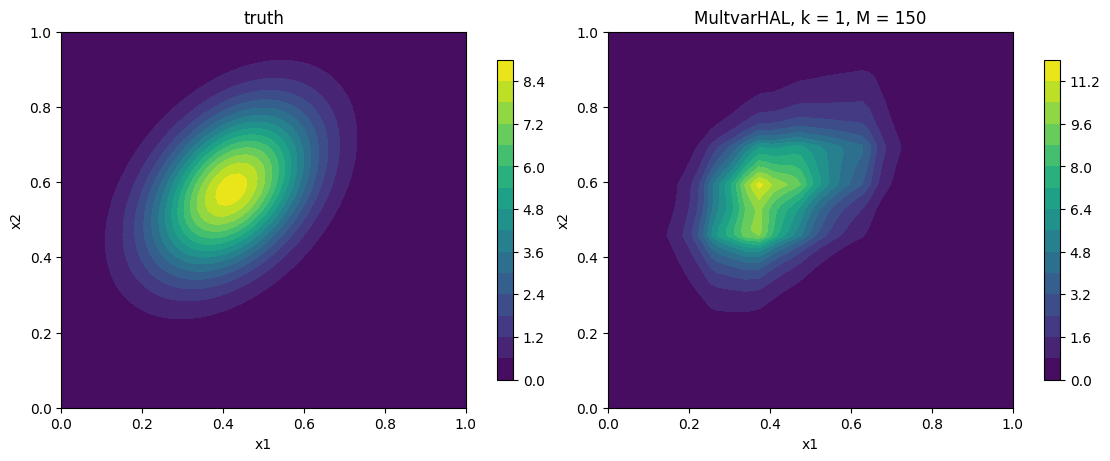

In [4]:
model = MultvarHAL(k=k, norm_constraint=best_M, support=truth.bounds).fit(pd.concat([data, holdout]))
axis = np.linspace(0, 1, 60)
mesh_x1, mesh_x2 = np.meshgrid(axis, axis)
points = np.column_stack([mesh_x1.ravel(), mesh_x2.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, values, title in ((axes[0], truth.compute_density(points), "truth"),
                          (axes[1], model.get_density_at_points(points), f"MultvarHAL, k = {k}, M = {best_M:g}")):
    contour = ax.contourf(mesh_x1, mesh_x2, values.reshape(mesh_x1.shape), levels=15, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    fig.colorbar(contour, ax=ax, shrink=0.85)
plt.show()

## Which terms the fit uses

`selected_basis_summary()` counts, for each type of term, the coefficients larger than `selection_tol`
(default 1e-4) in absolute value (`count`) and adds up their absolute values (`abs_coefficient_sum`). The final
fit used all 400 points, so the basis is twice the size of the one above.

In [5]:
model.selected_basis_summary()

,term_type,section_size,count,abs_coefficient_sum
0,poly,0,3,34.986092
1,section-1,1,1324,103.637267
2,full,2,294,10.525556
